### Import necessary libraries

In [4]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

### Importing dataset

In [5]:
Claimaints_data=pd.read_csv(filepath_or_buffer="Claimaints.csv.csv")
Claimaints_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1335,34100,1,0.0,1.0,0.0,NaN,0.576
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


### 3. Data understanding

In [7]:
Claimaints_data.shape

(1340, 7)

In [8]:
Claimaints_data.dtypes

CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

In [9]:
Claimaint_datas.isnull().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

### Data preparation

### Removing null valued row as missing value in model bulding will cause an issue

In [6]:
Claimaint_data1=Claimaints_data.dropna(subset=["CLMSEX","CLMINSUR","SEATBELT","CLMAGE"]) # or you can use only Claimaint_data1=Claimaint_data.dropna()

In [10]:
Claimaint_data1.isna().sum()

CASENUM     0
ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

In [21]:
Claimaint_data1.duplicated().sum()

np.int64(0)

In [19]:
Claimaint_data1.shape

(1096, 7)

### Seperate your input and output

In [7]:
y=Claimaint_data1["ATTORNEY"]
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

244 null rows have been removed

In [8]:
x=Claimaint_data1.iloc[:, 2:]
x

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


### 5.Model building

In [9]:
from sklearn.linear_model import LogisticRegression
Logisct_model=LogisticRegression()

**Test train split**

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(x,y,test_size=0.20, shuffle=True) # splitting data for test its 20 percent and training 80 percent

In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(x,y,test_size=0.20, shuffle=True, random_state=1) # to get same set of sample while shuffling random = any integer

In [25]:
X_train

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
473,0.0,1.0,0.0,6.0,5.505
557,0.0,1.0,0.0,30.0,0.565
3,0.0,1.0,1.0,31.0,0.037
426,1.0,1.0,0.0,10.0,0.385
867,1.0,1.0,0.0,33.0,1.000
...,...,...,...,...,...
1040,1.0,1.0,0.0,45.0,1.903
879,1.0,0.0,0.0,3.0,0.051
1104,1.0,1.0,0.0,46.0,4.010
285,1.0,1.0,0.0,7.0,7.450


### 6. Model training

In [11]:
Logisct_model.fit(X_train,y_train) #providing only 80 percent of training data splitted above

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


### 7. Model testing

**Training data**

In [12]:
y_predict_train=Logisct_model.predict(X_train)
y_predict_train

array([1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1,
       1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1,
       0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,

**Test data**

In [13]:
y_predict_test=Logisct_model.predict(X_test)
y_predict_test

array([1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0,
       1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1])

### 8.Model evaluation

**Training data evaluation**

In [20]:
from sklearn.metrics import accuracy_score
Score_train=accuracy_score(y_true=y_train, y_pred=y_predict_train)
Score_train

0.702054794520548

**Test evaluation**

In [21]:
from sklearn.metrics import accuracy_score
Score_test=accuracy_score(y_true=y_test, y_pred=y_predict_test)
Score_test

0.7227272727272728

#conclusion: Average of test done for training and test data is 70 percentage. Real world prediction also shuld be 70 percentage accuracy as we tested with unknown data as well

### The model is 70 percent accuracy

### Evaluation metrics (important evaluation metrics to be imported)

In [17]:
from sklearn.metrics import accuracy_score,auc,roc_auc_score,confusion_matrix,classification_report, roc_curve

In [15]:
print(classification_report(y_true=y_train, y_pred=y_predict_train)) #need to use print so that the scores come in new line or else will be jumbled

              precision    recall  f1-score   support

           0       0.77      0.65      0.71       454
           1       0.68      0.79      0.73       422

    accuracy                           0.72       876
   macro avg       0.72      0.72      0.72       876
weighted avg       0.73      0.72      0.72       876



In [16]:
print(confusion_matrix(y_true=y_train, y_pred=y_predict_train))

[[297 157]
 [ 89 333]]


### ROC = Receiver operating characteristic

### Area under this curve

0.7216422740463913


Text(0, 0.5, 'True Positive Rate')

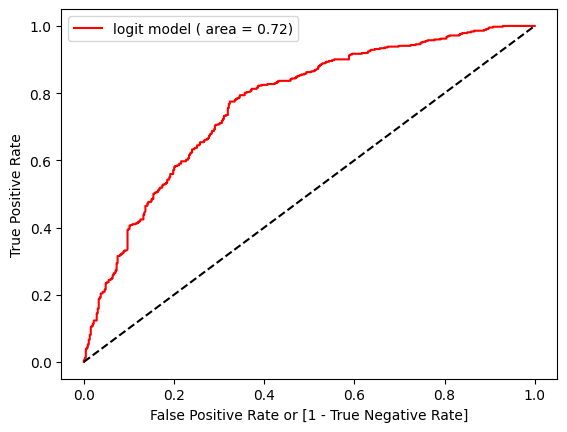

In [35]:
from sklearn.metrics import accuracy_score,auc,roc_auc_score,confusion_matrix,classification_report, roc_curve #included roc_curve
fpr, tpr, thresholds = roc_curve(y_train, Logisct_model.predict_proba (X_train) [:,1])

auc = roc_auc_score(y_train, y_predict_train)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.legend()
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

0.6876680107526881


Text(0, 0.5, 'True Positive Rate')

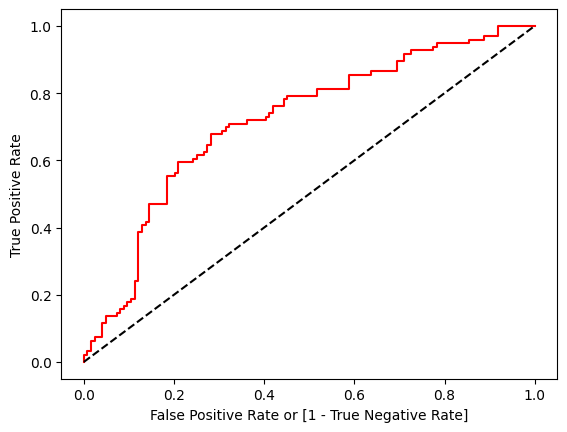

In [25]:
from sklearn.metrics import accuracy_score,auc,roc_auc_score,confusion_matrix,classification_report, roc_curve #included roc_curve
fpr, tpr, thresholds = roc_curve(y_test, Logisct_model.predict_proba (X_test) [:,1]) # slicing is needed as it needs 

auc = roc_auc_score(y_test, y_predict_test)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

,0,1
0,0.409188,5.908121e-01
1,0.313250,6.867503e-01
2,0.683426,3.165744e-01
3,0.912635,8.736532e-02
4,0.322032,6.779684e-01
...,...,...
215,1.000000,1.338700e-08
216,0.734259,2.657405e-01
217,0.444369,5.556308e-01
218,0.516702,4.832983e-01


### Area under this curve

### 9. Model deployment

In [58]:
from pickle import dump
dump(obj=Logisct_model, file=open(file="Logistic_inteligence.pkl",mode='wb'))
from pickle import load
Claimant=load(file=open(file="Logistic_inteligence.pkl",
    mode='rb'))
Claimant

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1335,0.0,1.0,0.0,NaN,0.576
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177
